# This is a notebook that predicts car used car value from Craigslist

### About the project
Craigslist is the world's largest collection of used vehicles for sale. Using data from this platform, this notebook will create a ML model to predict the true value of an used car based on its features.

Data is coming from [kaggle](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data) and contains 26 features.

### Project Steps
- Environment creation
- Data collection
- Data preparation
- Exploratory Data Analysis
- Feature Engineering
- Model development
- Results

### Step 0: Environment creation

This step involvees download of the required packages and their import into the working environment

In [ ]:
#%pip install numpy; pandas; matplotlib; scikit-learn; kagglehub; xgboost

In [2]:
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

c:\D_Folder\GitFiles\DataScienceProjects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Step 1: Data Collection

Data will be downloaded from kaggle

Dataset features: <StringArray>
[          'id',          'url',       'region',   'region_url',
        'price',         'year', 'manufacturer',        'model',
    'condition',    'cylinders',         'fuel',     'odometer',
 'title_status', 'transmission',          'VIN',        'drive',
         'size',         'type',  'paint_color',    'image_url',
  'description',       'county',        'state',          'lat',
         'long', 'posting_date']
Length: 26, dtype: str
<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  str    
 2   region        426880 non-null  str    
 3   region_url    426880 non-null  str    
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  str    
 7   model         421603 

<Axes: >

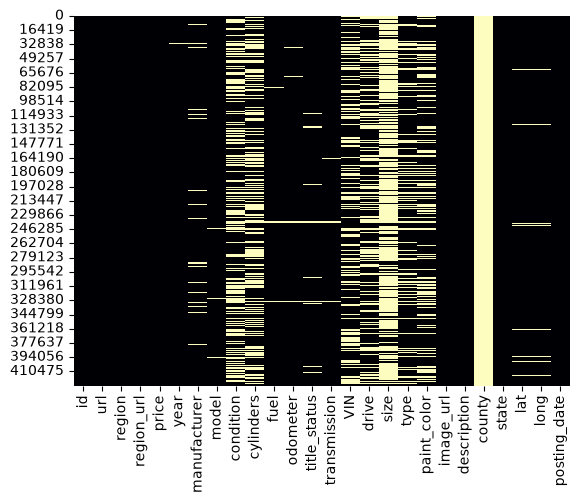

In [35]:
handle = 'austinreese/craigslist-carstrucks-data'
output_dir = 'Data'

#dataset = kagglehub.dataset_download(handle=handle, output_dir=output_dir)

df = pd.read_csv(f'{output_dir}\\vehicles.csv')
df.head()

print('Dataset features:', df.columns.values)
print('Dataset info:', df.info())
print('Null values:', df.isna().sum())
sns.heatmap(df.isnull(),cmap = 'magma',cbar = False)

#### Data collection conclusions
- There are a lot of missing values
- County column has no valu so it will be the first to be dropped
- Few numeric values:
    - useful: price(target), year, odometer
    - not useful: id, county, lat and long
- Loads of categorical features - need to check which one will have impact
- Condition feature has loads of missing values
- Cylinder feature can be mapped from string to numeric value

### Step 2: Data preparation

In [ ]:
#Eliminate irrelevant features
irrelevant_features = ['id', 'url', 'region_url', 'title_status', 'VIN', 'image_url', 'description', 'lat', 'long']

#df = df.drop(columns=irrelevant_features)
#Determine how much of each feature is nan and remove features with more than 50% missing values

length = len(df)
cutoff = 50 #Will discard data with cutoff values over 50%
col_missing_over_cutoff = []

for column in df.columns.values:
    missing_percent = (df[column].isna().sum()/length)*100
    if missing_percent > 50:
        col_missing_over_cutoff.append(column)

df = df.drop(columns = col_missing_over_cutoff)

df.columns.values

0                  prescott
1              fayetteville
2              florida keys
3    worcester / central MA
4                greensboro
Name: region, dtype: str